# Support Vector Machines for Clinical Signal Classification

## CAIR Workshop Series - Part 5A

**Learning Objectives:**
- Understand how SVMs find optimal decision boundaries
- Learn about kernels and the kernel trick for non-linear problems
- Visualize support vectors and margins in clinical data
- Compare linear, polynomial, and RBF kernels
- Apply SVMs to ECG beat classification
- Understand when to use SVM vs KNN vs Decision Trees

**Duration:** ~30 minutes

---

Support Vector Machines (SVMs) are powerful classifiers that find the **optimal boundary** between classes. Unlike KNN which looks at nearby points, SVMs find the widest possible "street" between classes.

In this notebook, we'll apply SVMs to **ECG beat classification** - distinguishing normal sinus beats, premature ventricular contractions (PVCs), and atrial fibrillation from a handful of summary measurements taken from each beat.


In [1]:
# Essential imports for clinical SVM analysis
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from matplotlib.colors import ListedColormap, BoundaryNorm
import warnings
warnings.filterwarnings('ignore')

# Set style for professional clinical presentations
plt.style.use('default')
sns.set_palette("husl")
np.random.seed(42)

print("🫀 Clinical Support Vector Machines: Ready for ECG Beat Analysis")
print("   This notebook demonstrates optimal boundary classification for bedside monitoring")


🫀 Clinical Support Vector Machines: Ready for ECG Beat Analysis
   This notebook demonstrates optimal boundary classification for bedside monitoring


## 1. ECG Beat Classification Dataset

We'll create a realistic dataset of **per-beat summary measurements** taken from a bedside
ECG monitor. Each row is one heartbeat, described by five numbers that a monitor can
compute in real time:

**Beat Features:**
- Dominant frequency (Hz) - spectral peak of the QRS complex; wide complexes are slower
- R amplitude (mV) - height of the tallest deflection of the beat
- Rate deviation (%) - how far this beat's RR interval sits from the running average
- QRS duration (ms) - how long ventricular depolarization takes
- Harmonic ratio - proportion of energy above the dominant peak (baseline irregularity)

**Beat Classes:**
- **Normal sinus**: narrow QRS (~90 ms), regular timing, clean baseline
- **PVC (premature ventricular contraction)**: wide QRS (>120 ms), tall bizarre complex, very early beat
- **Atrial fibrillation**: narrow QRS but irregularly irregular timing and a noisy baseline

> **A note on the data.** Every beat in this notebook is simulated from published
> electrocardiographic reference ranges. No real or identifiable patient data is used.


In [2]:
def generate_ecg_beat_data(n_samples=600):
    """
    Generate synthetic but realistic per-beat ECG summary measurements.

    Each row is one heartbeat described by five scalar features:
      dominant_freq_hz  - spectral peak of the QRS complex (Hz)
      r_amplitude_mv    - height of the R deflection (mV)
      rate_deviation    - RR interval departure from the running mean (%)
      qrs_duration_ms   - width of the QRS complex (ms)
      harmonic_ratio    - energy above the dominant peak (0-1)

    Values are simulated from published electrocardiographic reference
    ranges. No real patient data is used.
    """
    np.random.seed(42)
    n_per_class = n_samples // 3

    # NORMAL SINUS: narrow QRS, regular timing, clean baseline
    norm_freq = np.random.normal(11.0, 2.4, n_per_class)      # narrow complex -> higher peak
    norm_amp = np.random.normal(1.10, 0.30, n_per_class)      # typical R height 0.5-2.0 mV
    norm_dev = np.random.normal(4.0, 2.5, n_per_class)        # beat-to-beat variation is small
    norm_qrs = np.random.normal(92, 12, n_per_class)          # normal QRS ~80-100 ms
    norm_harm = np.random.beta(2, 5, n_per_class)             # quiet baseline

    # PVC: wide bizarre complex, tall R, arrives far too early
    pvc_freq = np.random.normal(7.6, 2.2, n_per_class)        # wide complex -> lower peak
    pvc_amp = np.random.normal(1.80, 0.45, n_per_class)       # tall, bizarre ectopic beat
    pvc_dev = np.random.normal(30.0, 11.0, n_per_class)       # premature: RR far below mean
    pvc_qrs = np.random.normal(146, 19, n_per_class)          # wide QRS, > 120 ms
    pvc_harm = np.random.beta(3, 4, n_per_class)              # moderate extra energy

    # ATRIAL FIBRILLATION: narrow QRS, irregularly irregular, noisy baseline
    af_freq = np.random.normal(12.8, 2.6, n_per_class)        # narrow complex, sharper peak
    af_amp = np.random.normal(0.80, 0.26, n_per_class)        # lower amplitude complexes
    af_dev = np.random.normal(20.0, 8.0, n_per_class)         # irregularly irregular rhythm
    af_qrs = np.random.normal(96, 14, n_per_class)            # conduction itself is normal
    af_harm = np.random.beta(5, 2, n_per_class)               # disorganized atrial baseline

    # Combine all data
    data = pd.DataFrame({
        'dominant_freq_hz': np.concatenate([norm_freq, pvc_freq, af_freq]),
        'r_amplitude_mv': np.concatenate([norm_amp, pvc_amp, af_amp]),
        'rate_deviation': np.concatenate([norm_dev, pvc_dev, af_dev]),
        'qrs_duration_ms': np.concatenate([norm_qrs, pvc_qrs, af_qrs]),
        'harmonic_ratio': np.concatenate([norm_harm, pvc_harm, af_harm]),
        'beat_type': (['Normal Sinus'] * n_per_class
                      + ['PVC'] * n_per_class
                      + ['Atrial Fibrillation'] * n_per_class)
    })

    # Keep every value inside a physiologically possible range
    data['dominant_freq_hz'] = data['dominant_freq_hz'].clip(2, 40)
    data['r_amplitude_mv'] = data['r_amplitude_mv'].clip(0.05, 4.0)
    data['rate_deviation'] = data['rate_deviation'].clip(0, 80)
    data['qrs_duration_ms'] = data['qrs_duration_ms'].clip(60, 220)
    data['harmonic_ratio'] = data['harmonic_ratio'].clip(0, 1)

    return data

# Generate ECG beat dataset
ecg_data = generate_ecg_beat_data(600)

print("🫀 ECG Beat Classification Dataset Generated (simulated, no real patient data)")
print(f"   Total beats: {len(ecg_data)}")
print(f"   Beat types: {ecg_data['beat_type'].value_counts().to_dict()}")

# Display statistics
print("\n📊 Per-Beat Measurement Statistics:")
ecg_data.groupby('beat_type')[['dominant_freq_hz', 'r_amplitude_mv', 'qrs_duration_ms']].mean().round(2)


🫀 ECG Beat Classification Dataset Generated (simulated, no real patient data)
   Total beats: 600
   Beat types: {'Normal Sinus': 200, 'PVC': 200, 'Atrial Fibrillation': 200}

📊 Per-Beat Measurement Statistics:


,dominant_freq_hz,r_amplitude_mv,qrs_duration_ms
beat_type,,,
Atrial Fibrillation,12.75,0.82,94.95
Normal Sinus,10.90,1.13,92.11
PVC,7.60,1.78,144.12


## 2. Visualizing Beat Morphology

Let's visualize how the three beat types cluster in the measurement space.


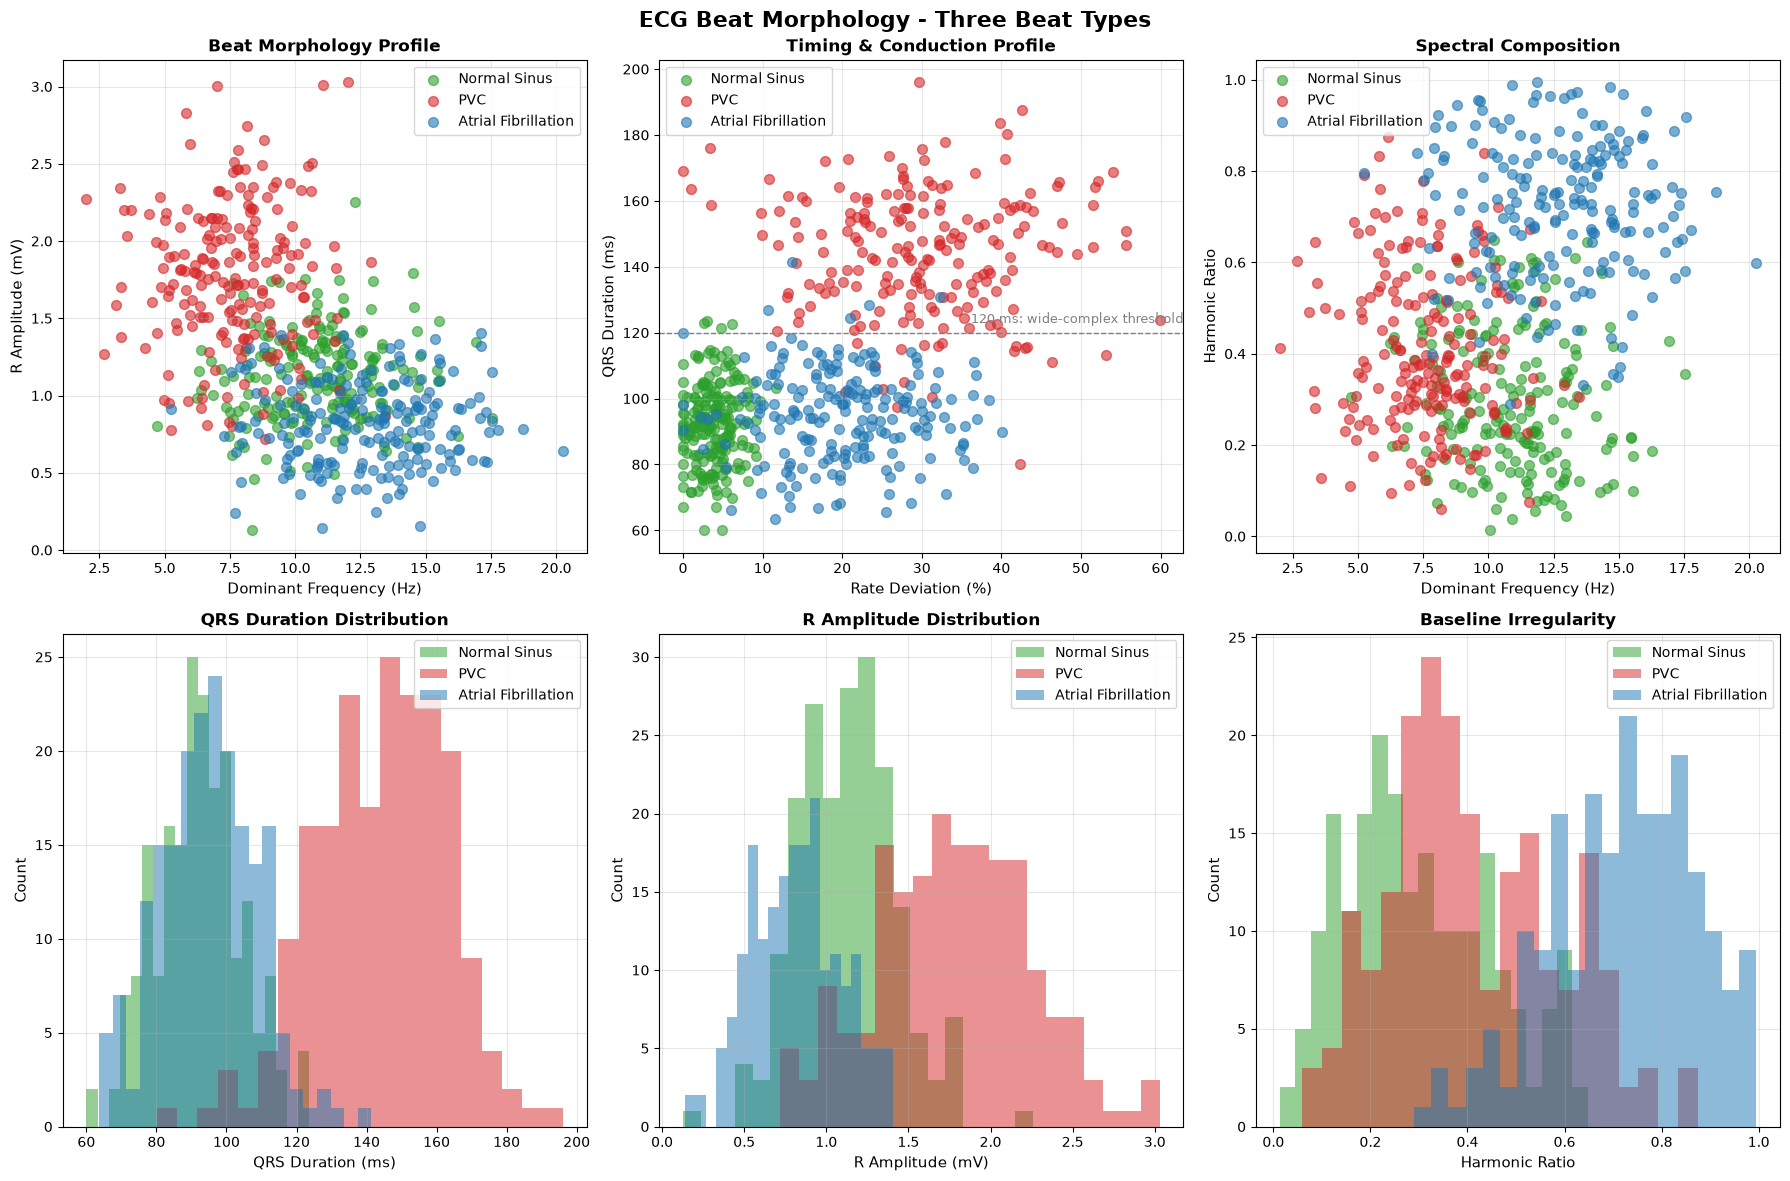


🔍 Morphology Observations:
   • Normal sinus: narrow QRS (~90 ms), regular timing (green)
   • PVC: wide QRS (>120 ms), tall early beat (red)
   • Atrial fibrillation: narrow QRS but irregular timing, noisy baseline (blue)
   • SVM will find optimal boundaries between these beat types


In [3]:
# Create visualization of beat morphology
fig, axes = plt.subplots(2, 3, figsize=(18, 12))
fig.suptitle('ECG Beat Morphology - Three Beat Types', fontsize=16, fontweight='bold')

# Define colors
colors = {'Normal Sinus': '#2CA02C', 'PVC': '#D62728', 'Atrial Fibrillation': '#1F77B4'}
BEAT_TYPES = ['Normal Sinus', 'PVC', 'Atrial Fibrillation']

# Plot 1: Dominant Frequency vs R Amplitude
ax = axes[0, 0]
for beat in BEAT_TYPES:
    mask = ecg_data['beat_type'] == beat
    ax.scatter(ecg_data[mask]['dominant_freq_hz'],
               ecg_data[mask]['r_amplitude_mv'],
               c=colors[beat], label=beat, alpha=0.6, s=50)
ax.set_xlabel('Dominant Frequency (Hz)', fontsize=11)
ax.set_ylabel('R Amplitude (mV)', fontsize=11)
ax.set_title('Beat Morphology Profile', fontweight='bold')
ax.legend()
ax.grid(True, alpha=0.3)

# Plot 2: Rate Deviation vs QRS Duration
ax = axes[0, 1]
for beat in BEAT_TYPES:
    mask = ecg_data['beat_type'] == beat
    ax.scatter(ecg_data[mask]['rate_deviation'],
               ecg_data[mask]['qrs_duration_ms'],
               c=colors[beat], label=beat, alpha=0.6, s=50)
ax.axhline(120, color='grey', linestyle='--', linewidth=1)
ax.text(ax.get_xlim()[1], 122, ' 120 ms: wide-complex threshold',
        ha='right', va='bottom', fontsize=9, color='grey')
ax.set_xlabel('Rate Deviation (%)', fontsize=11)
ax.set_ylabel('QRS Duration (ms)', fontsize=11)
ax.set_title('Timing & Conduction Profile', fontweight='bold')
ax.legend()
ax.grid(True, alpha=0.3)

# Plot 3: Dominant Frequency vs Harmonic Ratio
ax = axes[0, 2]
for beat in BEAT_TYPES:
    mask = ecg_data['beat_type'] == beat
    ax.scatter(ecg_data[mask]['dominant_freq_hz'],
               ecg_data[mask]['harmonic_ratio'],
               c=colors[beat], label=beat, alpha=0.6, s=50)
ax.set_xlabel('Dominant Frequency (Hz)', fontsize=11)
ax.set_ylabel('Harmonic Ratio', fontsize=11)
ax.set_title('Spectral Composition', fontweight='bold')
ax.legend()
ax.grid(True, alpha=0.3)

# Plot 4: QRS Duration Distribution
ax = axes[1, 0]
for beat in BEAT_TYPES:
    mask = ecg_data['beat_type'] == beat
    ax.hist(ecg_data[mask]['qrs_duration_ms'], bins=20, alpha=0.5,
            label=beat, color=colors[beat])
ax.set_xlabel('QRS Duration (ms)', fontsize=11)
ax.set_ylabel('Count', fontsize=11)
ax.set_title('QRS Duration Distribution', fontweight='bold')
ax.legend()
ax.grid(True, alpha=0.3)

# Plot 5: R Amplitude Distribution
ax = axes[1, 1]
for beat in BEAT_TYPES:
    mask = ecg_data['beat_type'] == beat
    ax.hist(ecg_data[mask]['r_amplitude_mv'], bins=20, alpha=0.5,
            label=beat, color=colors[beat])
ax.set_xlabel('R Amplitude (mV)', fontsize=11)
ax.set_ylabel('Count', fontsize=11)
ax.set_title('R Amplitude Distribution', fontweight='bold')
ax.legend()
ax.grid(True, alpha=0.3)

# Plot 6: Harmonic Ratio Distribution
ax = axes[1, 2]
for beat in BEAT_TYPES:
    mask = ecg_data['beat_type'] == beat
    ax.hist(ecg_data[mask]['harmonic_ratio'], bins=20, alpha=0.5,
            label=beat, color=colors[beat])
ax.set_xlabel('Harmonic Ratio', fontsize=11)
ax.set_ylabel('Count', fontsize=11)
ax.set_title('Baseline Irregularity', fontweight='bold')
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("\n🔍 Morphology Observations:")
print("   • Normal sinus: narrow QRS (~90 ms), regular timing (green)")
print("   • PVC: wide QRS (>120 ms), tall early beat (red)")
print("   • Atrial fibrillation: narrow QRS but irregular timing, noisy baseline (blue)")
print("   • SVM will find optimal boundaries between these beat types")


## 3. How SVM Works: Maximum Margin Classification

SVM finds the decision boundary that maximizes the **margin** - the distance to the nearest training points (support vectors).

**Key Concepts:**
1. **Decision Boundary**: Line/plane separating classes
2. **Margin**: "Width of the street" between classes
3. **Support Vectors**: Points that define the margin
4. **Kernel Trick**: Transform data for non-linear boundaries

Let's start with a linear SVM!

In [4]:
# Prepare data
X = ecg_data[['dominant_freq_hz', 'r_amplitude_mv', 'rate_deviation',
              'qrs_duration_ms', 'harmonic_ratio']]
y = ecg_data['beat_type']

# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2,
                                                      random_state=42, stratify=y)

# Scale features (CRITICAL for SVM!)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("⚙️  Data Preparation Complete")
print(f"   Training beats: {len(X_train)}")
print(f"   Testing beats:  {len(X_test)}")
print(f"   Features: {list(X.columns)}")

# Train Linear SVM
svm_linear = SVC(kernel='linear', C=1.0, random_state=42)
svm_linear.fit(X_train_scaled, y_train)

# Evaluate
train_acc = svm_linear.score(X_train_scaled, y_train)
test_acc = svm_linear.score(X_test_scaled, y_test)
y_pred = svm_linear.predict(X_test_scaled)

print("\n🎯 Linear SVM Results")
print("=" * 60)
print(f"Training Accuracy: {train_acc:.3f}")
print(f"Testing Accuracy:  {test_acc:.3f}")
print(f"Number of Support Vectors: {svm_linear.n_support_}")
for cls, n_sv in zip(svm_linear.classes_, svm_linear.n_support_):
    print(f"   {cls}: {n_sv}")

print("\n📊 Classification Report:")
print(classification_report(y_test, y_pred))

print("\n💡 What are Support Vectors?")
print("   Support vectors are the critical training points that define the decision boundary.")
print("   They are the 'closest' points from each class that determine the margin.")
print(f"   Out of {len(X_train)} training beats, only {svm_linear.n_support_.sum()} are support vectors!")


⚙️  Data Preparation Complete
   Training beats: 480
   Testing beats:  120
   Features: ['dominant_freq_hz', 'r_amplitude_mv', 'rate_deviation', 'qrs_duration_ms', 'harmonic_ratio']

🎯 Linear SVM Results
Training Accuracy: 0.985
Testing Accuracy:  0.983
Number of Support Vectors: [18 17 10]
   Atrial Fibrillation: 18
   Normal Sinus: 17
   PVC: 10

📊 Classification Report:
                     precision    recall  f1-score   support

Atrial Fibrillation       0.95      1.00      0.98        40
       Normal Sinus       1.00      0.95      0.97        40
                PVC       1.00      1.00      1.00        40

           accuracy                           0.98       120
          macro avg       0.98      0.98      0.98       120
       weighted avg       0.98      0.98      0.98       120


💡 What are Support Vectors?
   Support vectors are the critical training points that define the decision boundary.
   They are the 'closest' points from each class that determine the margin.
 

## 4. Visualizing SVM Decision Boundaries

Let's visualize how SVM creates decision boundaries and margins in 2D feature space.

📊 Linear SVM Decision Boundary
   Amber circles = support vectors (the critical beats defining the boundary)



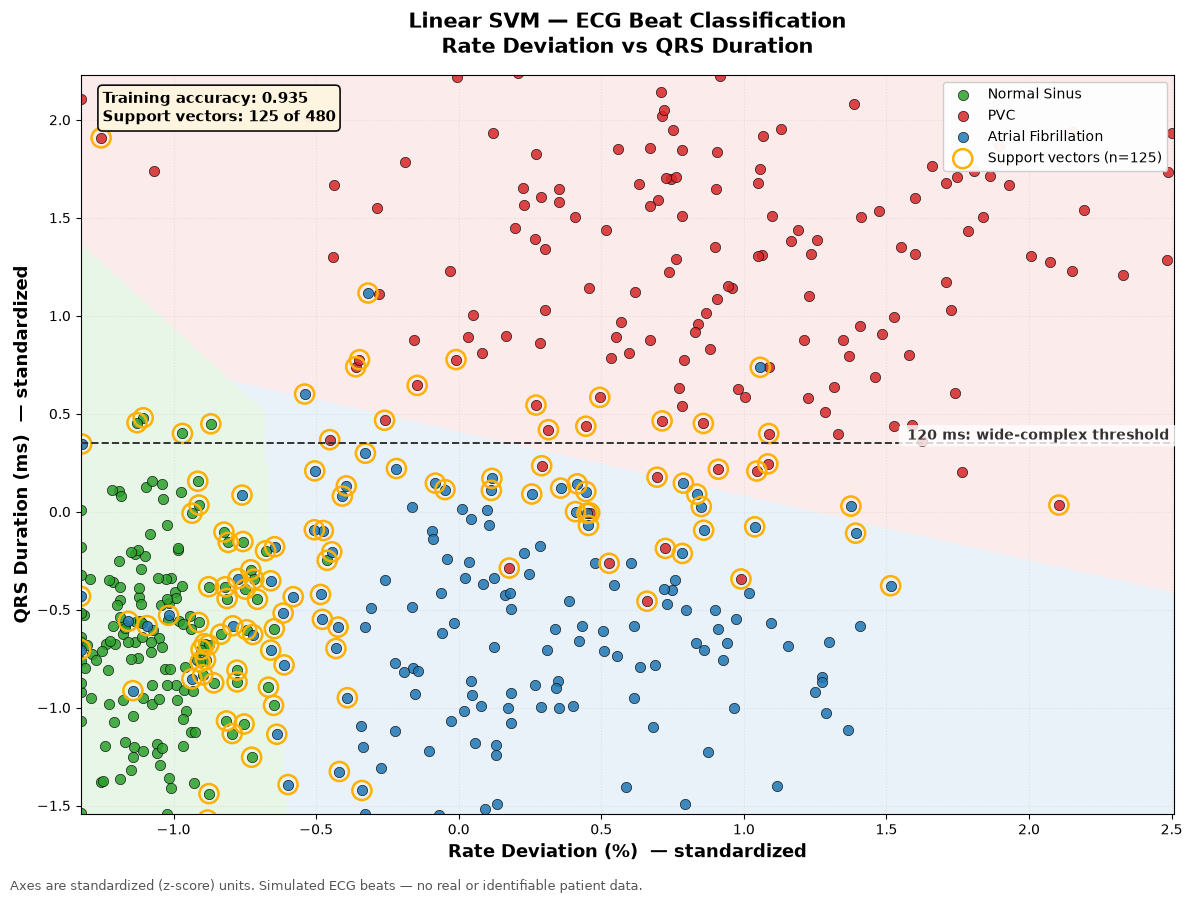


💡 Key Observations:
   • Decision boundaries are straight lines (linear kernel)
   • Support vectors (amber circles) are the beats closest to the boundaries
   • Only these critical beats determine the decision boundary
   • Other beats could be removed without changing the model!


In [5]:
# Colours used consistently for the three beat types throughout the notebook
BEAT_COLORS = {'Normal Sinus': '#2CA02C', 'PVC': '#D62728', 'Atrial Fibrillation': '#1F77B4'}
BEAT_COLORS_LIGHT = {'Normal Sinus': '#D5EFD5', 'PVC': '#FADCDC', 'Atrial Fibrillation': '#D8E7F5'}

# Readable names, in the same order as the columns of X
feature_names = ['Dominant Frequency (Hz)', 'R Amplitude (mV)', 'Rate Deviation (%)',
                 'QRS Duration (ms)', 'Harmonic Ratio']


def plot_svm_decision_boundary(X_data, y_data, feature1_idx, feature2_idx,
                                feature_names, kernel='linear', title='',
                                ref_y_raw=None, ref_y_label=''):
    """
    Plot an SVM decision boundary with the support vectors highlighted.

    X_data is already standardized, so both axes are in standard deviations
    away from the mean beat (z-scores). Pass ref_y_raw to draw a clinical
    reference line (given in the feature's original units) across the plot.
    """
    # Select two features
    X_2d = X_data[:, [feature1_idx, feature2_idx]]

    # Train SVM on 2D data
    svm = SVC(kernel=kernel, C=1.0, gamma='scale', random_state=42)
    svm.fit(X_2d, y_data)

    # Create figure
    fig, ax = plt.subplots(1, 1, figsize=(12, 9))

    # Create mesh - use percentiles to avoid outliers extending bounds too far
    x_min, x_max = np.percentile(X_2d[:, 0], 1), np.percentile(X_2d[:, 0], 99)
    y_min, y_max = np.percentile(X_2d[:, 1], 1), np.percentile(X_2d[:, 1], 99)
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300),
                         np.linspace(y_min, y_max, 300))

    # Predict - use the model's classes_ to ensure correct mapping
    Z = svm.predict(np.c_[xx.ravel(), yy.ravel()])

    # Map predictions to integers based on model's class order
    class_to_int = {cls: i for i, cls in enumerate(svm.classes_)}
    Z_numeric = np.array([class_to_int[z] for z in Z])
    Z_numeric = Z_numeric.reshape(xx.shape)

    # Plot decision regions with proper discrete color mapping
    colors_ordered = [BEAT_COLORS_LIGHT[cls] for cls in svm.classes_]
    cmap_light = ListedColormap(colors_ordered)
    bounds = np.arange(-0.5, len(svm.classes_) + 0.5, 1)
    norm = BoundaryNorm(bounds, cmap_light.N)
    ax.pcolormesh(xx, yy, Z_numeric, cmap=cmap_light, norm=norm, alpha=0.55, shading='auto')

    # Plot training points
    for beat in ['Normal Sinus', 'PVC', 'Atrial Fibrillation']:
        mask = y_data == beat
        ax.scatter(X_2d[mask, 0], X_2d[mask, 1],
                  c=BEAT_COLORS[beat], label=beat,
                  edgecolors='black', linewidth=0.5, s=55, alpha=0.85)

    # Highlight support vectors
    support_vectors = X_2d[svm.support_]
    ax.scatter(support_vectors[:, 0], support_vectors[:, 1],
               s=190, linewidth=1.8, facecolors='none', edgecolors='#FFB000',
               label=f'Support vectors (n={len(svm.support_)})')

    # Optional clinical reference line, converted into standardized units
    if ref_y_raw is not None:
        ref_y = (ref_y_raw - scaler.mean_[feature2_idx]) / scaler.scale_[feature2_idx]
        if y_min < ref_y < y_max:
            ax.axhline(ref_y, color='#333333', linestyle='--', linewidth=1.4, zorder=3)
            ax.text(x_max, ref_y, f' {ref_y_label} ', ha='right', va='bottom',
                    fontsize=10, color='#333333', fontweight='bold',
                    bbox=dict(boxstyle='round,pad=0.25', facecolor='white',
                              edgecolor='none', alpha=0.8))

    # Labels and title
    ax.set_xlabel(f'{feature_names[feature1_idx]}  — standardized', fontsize=13, fontweight='bold')
    ax.set_ylabel(f'{feature_names[feature2_idx]}  — standardized', fontsize=13, fontweight='bold')
    ax.set_title(title, fontweight='bold', fontsize=15, pad=16)
    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)
    ax.legend(loc='upper right', fontsize=10, framealpha=0.95)
    ax.grid(True, alpha=0.25, linestyle=':')

    # Add accuracy
    accuracy = svm.score(X_2d, y_data)
    ax.text(0.02, 0.98,
            f'Training accuracy: {accuracy:.3f}\n'
            f'Support vectors: {len(svm.support_)} of {len(X_2d)}',
           transform=ax.transAxes, fontsize=11, fontweight='bold',
           verticalalignment='top',
           bbox=dict(boxstyle='round', facecolor='#FFF6E0', alpha=0.95,
                    edgecolor='black', linewidth=1.2))

    # Footnote: axes are z-scores, and the data is simulated
    fig.text(0.01, 0.005,
             'Axes are standardized (z-score) units. Simulated ECG beats — '
             'no real or identifiable patient data.',
             fontsize=9, color='#555555')

    plt.tight_layout(rect=[0, 0.02, 1, 1])
    plt.show()

    return svm


print("📊 Linear SVM Decision Boundary")
print("   Amber circles = support vectors (the critical beats defining the boundary)\n")
svm_vis = plot_svm_decision_boundary(X_train_scaled, y_train, 2, 3,
                                      feature_names, kernel='linear',
                                      title='Linear SVM — ECG Beat Classification\nRate Deviation vs QRS Duration',
                                      ref_y_raw=120, ref_y_label='120 ms: wide-complex threshold')

print("\n💡 Key Observations:")
print("   • Decision boundaries are straight lines (linear kernel)")
print("   • Support vectors (amber circles) are the beats closest to the boundaries")
print("   • Only these critical beats determine the decision boundary")
print("   • Other beats could be removed without changing the model!")


## 5. The Kernel Trick: Non-Linear Boundaries

Real-world clinical measurements often require **non-linear** boundaries. SVM uses the **kernel trick** to handle this!

**Common Kernels:**
- **Linear**: `K(x, x') = x · x'` - Straight boundaries
- **Polynomial**: `K(x, x') = (γx · x' + r)^d` - Curved boundaries
- **RBF (Radial Basis Function)**: `K(x, x') = exp(-γ||x - x'||²)` - Flexible boundaries
- **Sigmoid**: `K(x, x') = tanh(γx · x' + r)` - Neural network-like

Let's compare different kernels!



🔍 Linear Kernel
Training Accuracy: 0.985
Testing Accuracy:  0.983
Support Vectors: 45 / 480


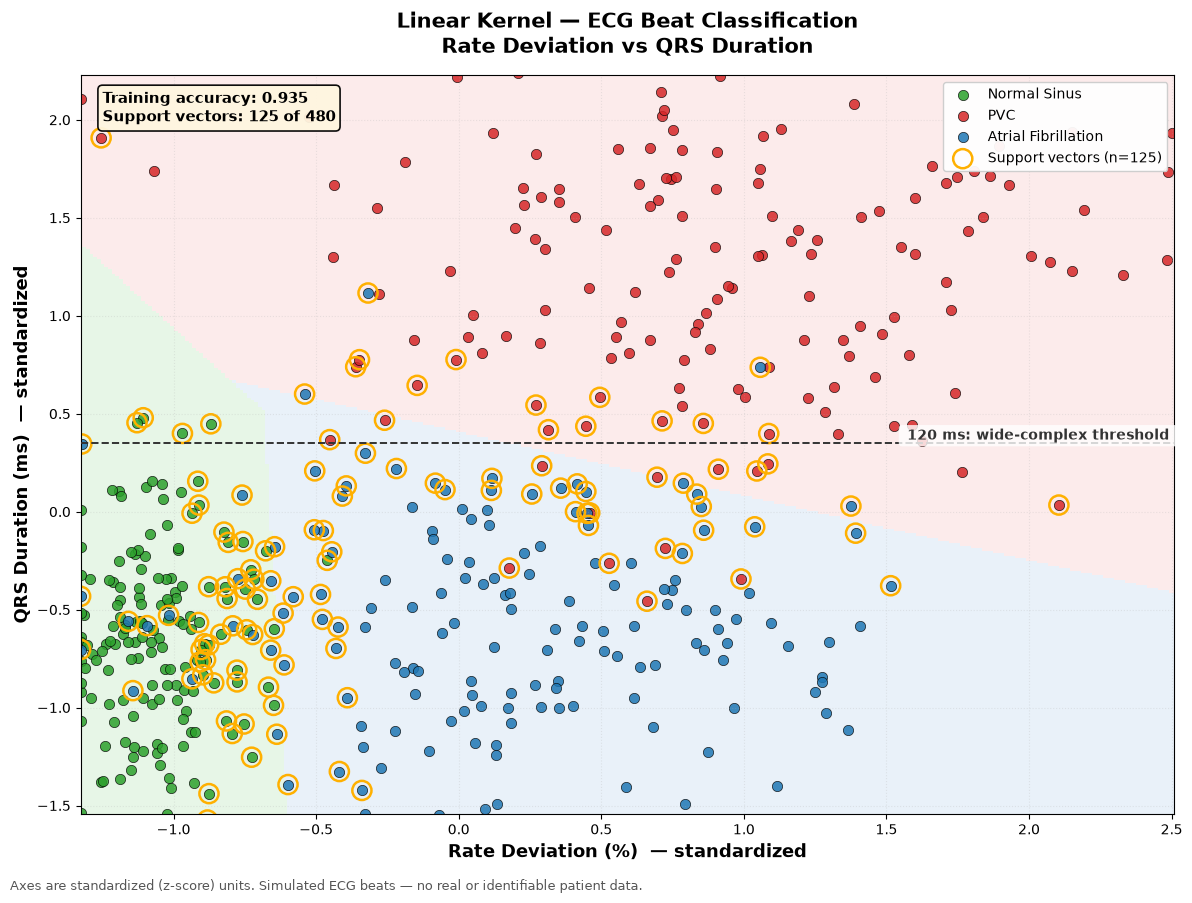

   ✓ Creates straight decision boundaries
   ✓ Fast and interpretable
   ✗ Limited to linearly separable problems

🔍 Polynomial (degree=3) Kernel
Training Accuracy: 0.960
Testing Accuracy:  0.958
Support Vectors: 128 / 480


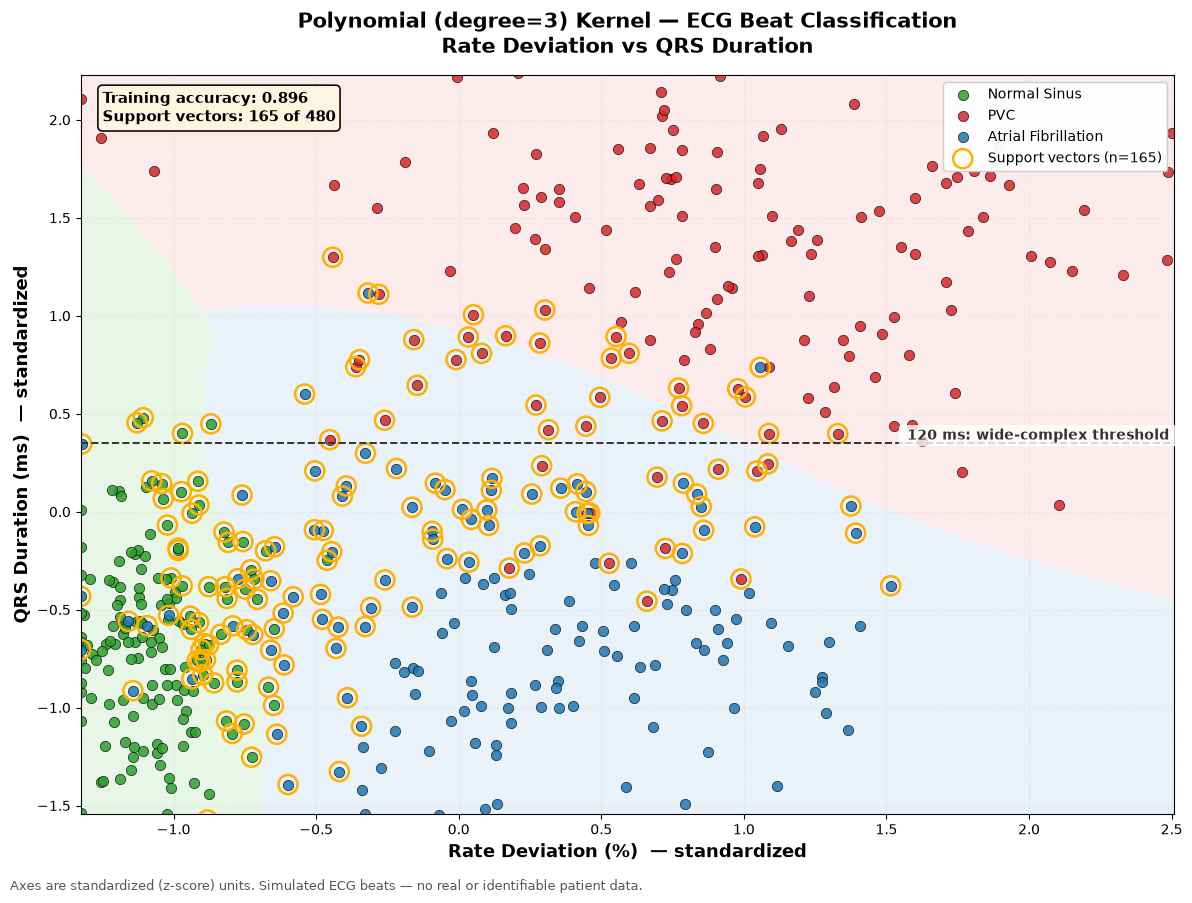

   ✓ Creates curved, polynomial boundaries
   ✓ Good for moderately complex patterns
   ✗ Can overfit with high degree

🔍 RBF (Radial Basis Function) Kernel
Training Accuracy: 0.985
Testing Accuracy:  0.975
Support Vectors: 95 / 480


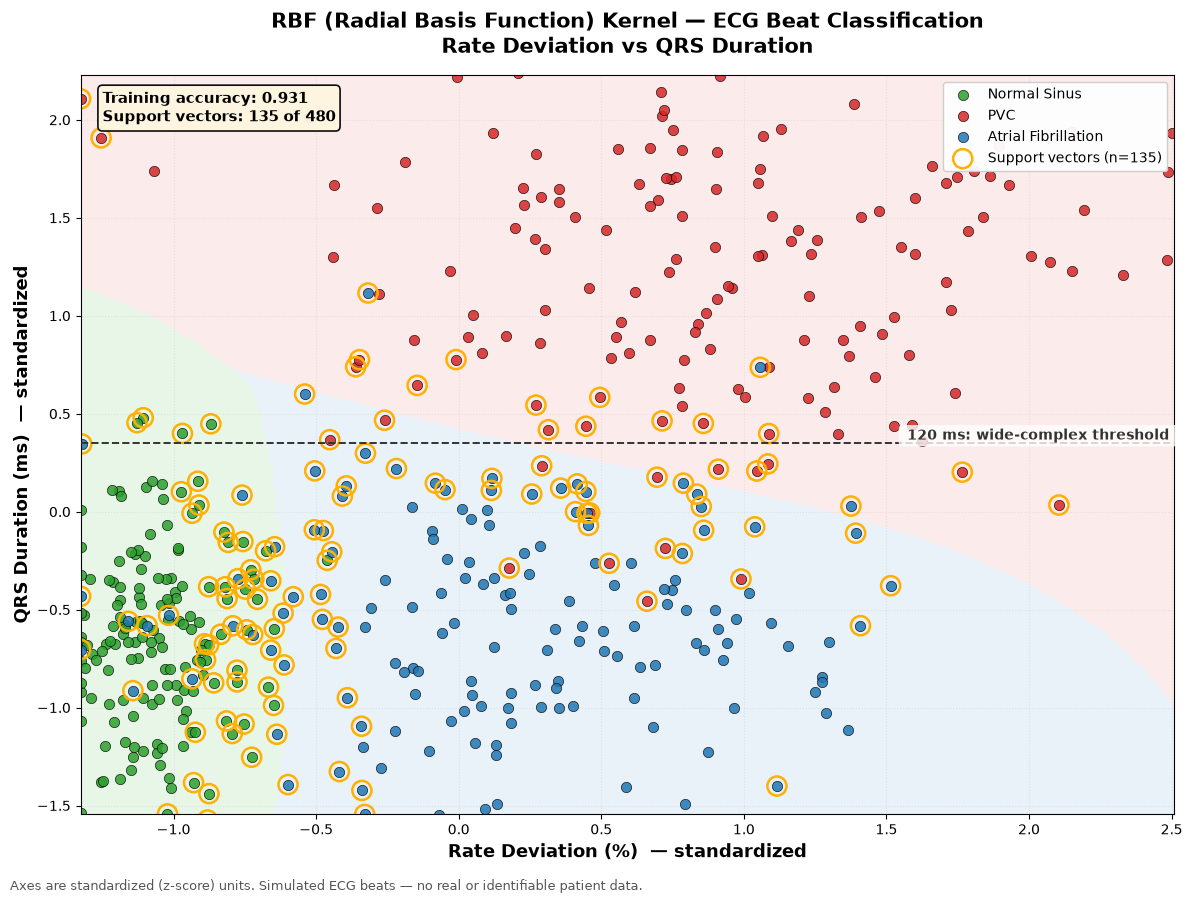

   ✓ Creates very flexible boundaries
   ✓ Often the best choice for complex problems
   ✗ Requires careful parameter tuning


💡 Kernel Selection Guidelines:
📍 Use Linear kernel when:
   • Data is linearly separable
   • High-dimensional sparse data (clinical notes, text)
   • Speed and interpretability are priorities

📍 Use RBF kernel when:
   • No prior knowledge of data structure
   • Complex, non-linear patterns expected
   • Most common choice for physiological signal features

📍 Use Polynomial kernel when:
   • Moderate non-linearity
   • Known polynomial relationships
   • Image processing tasks


In [6]:
# Compare different kernels
kernels = ['linear', 'poly', 'rbf']
kernel_names = ['Linear', 'Polynomial (degree=3)', 'RBF (Radial Basis Function)']

for kernel, name in zip(kernels, kernel_names):
    print(f"\n{'='*70}")
    print(f"🔍 {name} Kernel")
    print(f"{'='*70}")

    # Train SVM
    if kernel == 'poly':
        svm = SVC(kernel=kernel, degree=3, C=1.0, gamma='scale', random_state=42)
    else:
        svm = SVC(kernel=kernel, C=1.0, gamma='scale', random_state=42)

    svm.fit(X_train_scaled, y_train)

    # Evaluate
    train_acc = svm.score(X_train_scaled, y_train)
    test_acc = svm.score(X_test_scaled, y_test)

    print(f"Training Accuracy: {train_acc:.3f}")
    print(f"Testing Accuracy:  {test_acc:.3f}")
    print(f"Support Vectors: {svm.n_support_.sum()} / {len(X_train)}")

    # Visualize
    title = f'{name} Kernel — ECG Beat Classification\nRate Deviation vs QRS Duration'
    plot_svm_decision_boundary(X_train_scaled, y_train, 2, 3,
                               feature_names, kernel=kernel, title=title,
                               ref_y_raw=120, ref_y_label='120 ms: wide-complex threshold')

    if kernel == 'linear':
        print("   ✓ Creates straight decision boundaries")
        print("   ✓ Fast and interpretable")
        print("   ✗ Limited to linearly separable problems")
    elif kernel == 'poly':
        print("   ✓ Creates curved, polynomial boundaries")
        print("   ✓ Good for moderately complex patterns")
        print("   ✗ Can overfit with high degree")
    elif kernel == 'rbf':
        print("   ✓ Creates very flexible boundaries")
        print("   ✓ Often the best choice for complex problems")
        print("   ✗ Requires careful parameter tuning")

print("\n\n💡 Kernel Selection Guidelines:")
print("=" * 70)
print("📍 Use Linear kernel when:")
print("   • Data is linearly separable")
print("   • High-dimensional sparse data (clinical notes, text)")
print("   • Speed and interpretability are priorities")
print("\n📍 Use RBF kernel when:")
print("   • No prior knowledge of data structure")
print("   • Complex, non-linear patterns expected")
print("   • Most common choice for physiological signal features")
print("\n📍 Use Polynomial kernel when:")
print("   • Moderate non-linearity")
print("   • Known polynomial relationships")
print("   • Image processing tasks")


## 6. Hyperparameter Tuning: C and Gamma

SVM has critical hyperparameters that affect performance:

**C (Regularization):**
- Small C: Wide margin, more regularization, may underfit
- Large C: Narrow margin, less regularization, may overfit

**Gamma (for RBF/Poly kernels):**
- Small gamma: Far-reaching influence, smooth boundaries
- Large gamma: Close-range influence, wiggly boundaries

Let's find optimal parameters using grid search!

🔧 Hyperparameter Tuning with Grid Search
Testing parameter combinations...
   C values: [0.1, 1, 10, 100]
   Gamma values: ['scale', 0.001, 0.01, 0.1, 1]
   Total combinations: 20
Fitting 5 folds for each of 20 candidates, totalling 100 fits



✅ Grid Search Complete!

🏆 Best Parameters:
   C: 100
   Gamma: 0.1
   Best CV Score: 0.988

🎯 Optimized SVM Performance:
   Test Accuracy: 0.975
   Support Vectors: 43

📊 Classification Report (Optimized Model):
                     precision    recall  f1-score   support

Atrial Fibrillation       0.95      0.97      0.96        40
       Normal Sinus       1.00      0.95      0.97        40
                PVC       0.98      1.00      0.99        40

           accuracy                           0.97       120
          macro avg       0.98      0.97      0.97       120
       weighted avg       0.98      0.97      0.97       120



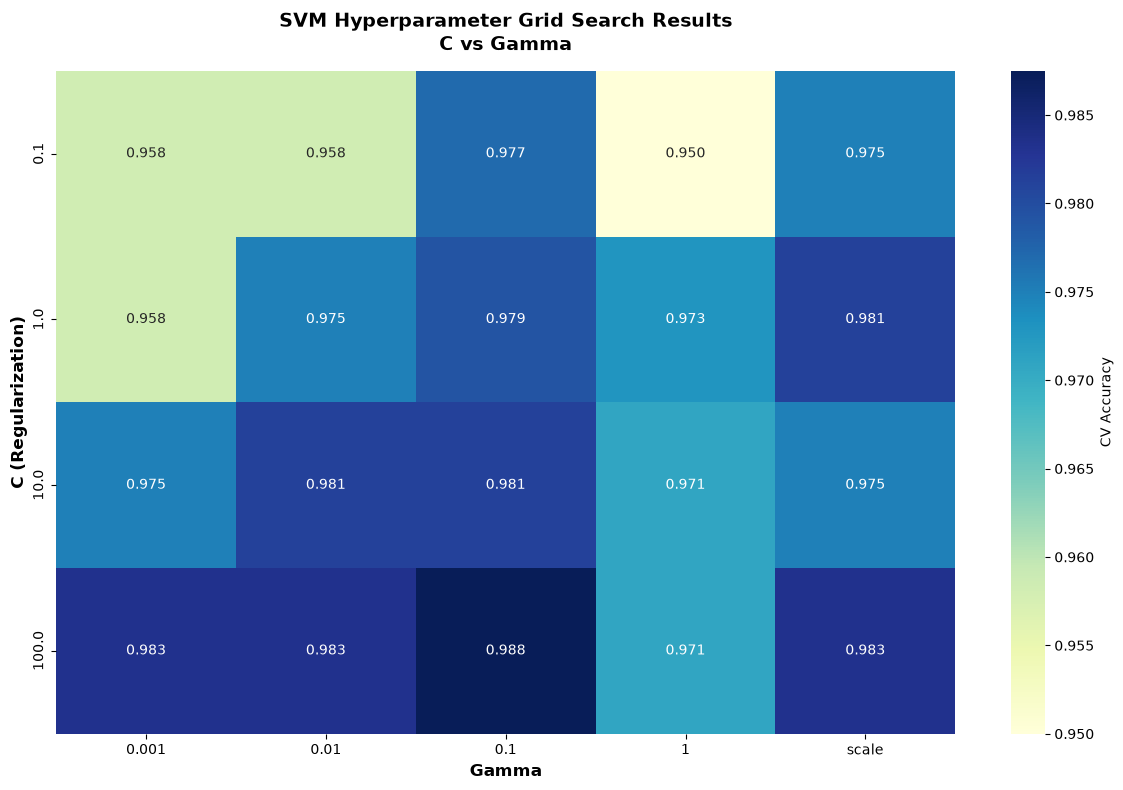


💡 Parameter Selection Insights:
   • Darker colors = Better accuracy
   • Bottom-left corner: Underfit (too much regularization)
   • Top-right corner: May overfit (too little regularization)
   • Sweet spot: Balance between C and gamma


In [7]:
print("🔧 Hyperparameter Tuning with Grid Search")
print("=" * 70)

# Define parameter grid
param_grid = {
    'C': [0.1, 1, 10, 100],
    'gamma': ['scale', 0.001, 0.01, 0.1, 1],
    'kernel': ['rbf']
}

print("Testing parameter combinations...")
print(f"   C values: {param_grid['C']}")
print(f"   Gamma values: {param_grid['gamma']}")
print(f"   Total combinations: {len(param_grid['C']) * len(param_grid['gamma'])}")

# Grid search with cross-validation
grid_search = GridSearchCV(SVC(), param_grid, cv=5, scoring='accuracy', 
                           verbose=1, n_jobs=-1)
grid_search.fit(X_train_scaled, y_train)

print("\n✅ Grid Search Complete!")
print("\n🏆 Best Parameters:")
print(f"   C: {grid_search.best_params_['C']}")
print(f"   Gamma: {grid_search.best_params_['gamma']}")
print(f"   Best CV Score: {grid_search.best_score_:.3f}")

# Train final model with best parameters
best_svm = grid_search.best_estimator_
test_acc = best_svm.score(X_test_scaled, y_test)

print(f"\n🎯 Optimized SVM Performance:")
print(f"   Test Accuracy: {test_acc:.3f}")
print(f"   Support Vectors: {best_svm.n_support_.sum()}")

# Detailed results
y_pred_best = best_svm.predict(X_test_scaled)
print("\n📊 Classification Report (Optimized Model):")
print(classification_report(y_test, y_pred_best))

# Visualize parameter effects
results_df = pd.DataFrame(grid_search.cv_results_)
pivot_table = results_df.pivot_table(values='mean_test_score', 
                                      index='param_C', 
                                      columns='param_gamma')

plt.figure(figsize=(12, 8))
sns.heatmap(pivot_table, annot=True, fmt='.3f', cmap='YlGnBu', 
            cbar_kws={'label': 'CV Accuracy'})
plt.title('SVM Hyperparameter Grid Search Results\nC vs Gamma', 
          fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Gamma', fontsize=12, fontweight='bold')
plt.ylabel('C (Regularization)', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

print("\n💡 Parameter Selection Insights:")
print("   • Darker colors = Better accuracy")
print("   • Bottom-left corner: Underfit (too much regularization)")
print("   • Top-right corner: May overfit (too little regularization)")
print("   • Sweet spot: Balance between C and gamma")

## 7. Classifying Unlabelled Beats

Let's test our optimized SVM on beats it has never seen.


In [8]:
def classify_ecg_beat(svm_model, scaler, features, beat_id):
    """
    Classify an unlabelled ECG beat and show the decision confidence.
    """
    # Scale input
    features_scaled = scaler.transform([features])

    # Predict
    prediction = svm_model.predict(features_scaled)[0]

    # Decision function (distance from boundary)
    decision_values = svm_model.decision_function(features_scaled)[0]

    print("\n" + "=" * 70)
    print(f"🫀 BEAT {beat_id} - CLASSIFICATION REPORT")
    print("=" * 70)

    print("\n📈 Per-Beat Measurements:")
    measurement_names = ['Dominant frequency (Hz)', 'R amplitude (mV)', 'Rate deviation (%)',
                         'QRS duration (ms)', 'Harmonic ratio']
    for name, value in zip(measurement_names, features):
        print(f"   {name:25}: {value:.2f}")

    print(f"\n🎯 Classification: {prediction}")

    print("\n📊 Decision Confidence (distance from boundary):")
    class_names = svm_model.classes_
    for cls, val in zip(class_names, decision_values):
        bar = '█' * int(abs(val) * 5)
        sign = '+' if val > 0 else '-'
        print(f"   {cls:22} {sign}{abs(val):6.3f} {bar}")

    # Confidence is the GAP between the best and second-best class score, not the
    # winning score on its own - a beat sitting between two classes has two
    # near-equal scores even when both are large.
    ranked = np.sort(decision_values)[::-1]
    margin = ranked[0] - ranked[1]

    print("\n💡 Interpretation:")
    print(f"   Margin over the runner-up class: {margin:.3f}")
    if margin > 1.0:
        print("   ✓ HIGH CONFIDENCE - beat type is clearly identified")
    elif margin > 0.4:
        print("   ⚠ MODERATE CONFIDENCE - recommend review of the rhythm strip")
    else:
        print("   ⚠ LOW CONFIDENCE - ambiguous morphology, flag for clinician review")

    print("=" * 70)

# Test cases
print("🫀 ECG BEAT CLASSIFICATION EXAMPLES\n")

# Beat 1: Clear normal sinus beat
normal_beat = [11.0, 1.15, 3.5, 90, 0.25]   # narrow QRS, regular, quiet baseline
classify_ecg_beat(best_svm, scaler, normal_beat, "001")

# Beat 2: Textbook PVC
pvc_beat = [7.2, 1.90, 33.0, 150, 0.45]     # wide QRS, tall, very early
classify_ecg_beat(best_svm, scaler, pvc_beat, "002")

# Beat 3: Atrial fibrillation
af_beat = [13.2, 0.75, 22.0, 95, 0.78]      # narrow QRS, irregular, noisy baseline
classify_ecg_beat(best_svm, scaler, af_beat, "003")

# Beat 4: Ambiguous case
# Beat 4: Borderline - a mildly wide complex that arrives almost on time
# (the picture a fusion beat or an aberrantly conducted beat presents)
ambiguous_beat = [10.5, 1.10, 8.0, 126, 0.55]
classify_ecg_beat(best_svm, scaler, ambiguous_beat, "004")


🫀 ECG BEAT CLASSIFICATION EXAMPLES


🫀 BEAT 001 - CLASSIFICATION REPORT

📈 Per-Beat Measurements:
   Dominant frequency (Hz)  : 11.00
   R amplitude (mV)         : 1.15
   Rate deviation (%)       : 3.50
   QRS duration (ms)        : 90.00
   Harmonic ratio           : 0.25

🎯 Classification: Normal Sinus

📊 Decision Confidence (distance from boundary):
   Atrial Fibrillation    - 0.286 █
   Normal Sinus           + 2.295 ███████████
   PVC                    + 0.790 ███

💡 Interpretation:
   Margin over the runner-up class: 1.505
   ✓ HIGH CONFIDENCE - beat type is clearly identified

🫀 BEAT 002 - CLASSIFICATION REPORT

📈 Per-Beat Measurements:
   Dominant frequency (Hz)  : 7.20
   R amplitude (mV)         : 1.90
   Rate deviation (%)       : 33.00
   QRS duration (ms)        : 150.00
   Harmonic ratio           : 0.45

🎯 Classification: PVC

📊 Decision Confidence (distance from boundary):
   Atrial Fibrillation    + 0.860 ████
   Normal Sinus           - 0.305 █
   PVC               

## 8. SVM vs Other Algorithms

Let's compare SVM with KNN and Decision Trees for ECG beat classification.


⚔️  ALGORITHM COMPARISON: SVM vs KNN vs Decision Tree

    Algorithm  Test Accuracy  CV Accuracy  Train Time (s)  Predict Time (s)
    SVM (RBF)       0.975000     0.987500        0.001000          0.001367
    KNN (k=5)       0.975000     0.977083        0.000582          0.002110
Decision Tree       0.958333     0.941667        0.001537          0.000925


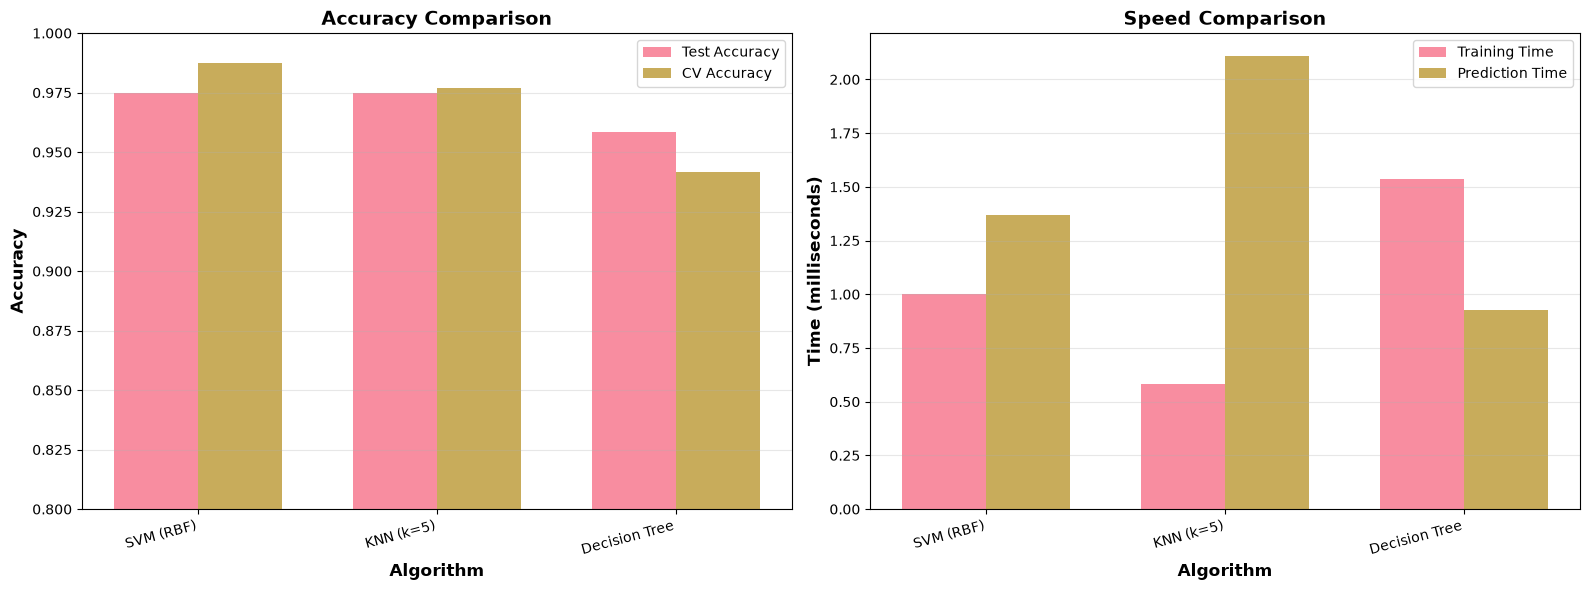



📊 DETAILED COMPARISON

🔵 SUPPORT VECTOR MACHINE (SVM):
   ✅ Strengths:
      • Excellent for high-dimensional data
      • Kernel trick handles non-linear boundaries
      • Works well with clear margins between classes
      • Memory efficient (only stores support vectors)
      • Strong theoretical foundation
   ❌ Weaknesses:
      • Slow on large datasets (O(n²) to O(n³))
      • Requires careful hyperparameter tuning
      • Requires feature scaling
      • Not interpretable (black box)

🟢 K-NEAREST NEIGHBORS (KNN):
   ✅ Strengths: Simple, no training, naturally multi-class
   ❌ Weaknesses: Slow predictions, curse of dimensionality

🟡 DECISION TREE:
   ✅ Strengths: Interpretable, fast, no scaling needed
   ❌ Weaknesses: Unstable, prone to overfitting


🫀 CLINICAL USE CASE RECOMMENDATIONS:

📍 Use SVM when:
   • High-dimensional physiological feature sets
   • Clear separation between beat classes
   • Need maximum accuracy (not real-time)
   • Example: ECG beat classification, hea

In [9]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
import time

print("⚔️  ALGORITHM COMPARISON: SVM vs KNN vs Decision Tree")
print("=" * 70)

# Train models
models = {
    'SVM (RBF)': best_svm,
    'KNN (k=5)': KNeighborsClassifier(n_neighbors=5),
    'Decision Tree': DecisionTreeClassifier(max_depth=10, random_state=42)
}

results = []

for name, model in models.items():
    if name != 'SVM (RBF)':  # SVM already trained
        # Train
        start = time.time()
        if 'KNN' in name:
            model.fit(X_train_scaled, y_train)
        else:
            model.fit(X_train, y_train)  # DT doesn't need scaling
        train_time = time.time() - start
    else:
        train_time = 0.001  # Already trained
    
    # Predict
    start = time.time()
    if 'KNN' in name or 'SVM' in name:
        predictions = model.predict(X_test_scaled)
        test_acc = model.score(X_test_scaled, y_test)
    else:
        predictions = model.predict(X_test)
        test_acc = model.score(X_test, y_test)
    pred_time = time.time() - start
    
    # Cross-validation
    if 'KNN' in name or 'SVM' in name:
        cv_scores = cross_val_score(model, X_train_scaled, y_train, cv=5)
    else:
        cv_scores = cross_val_score(model, X_train, y_train, cv=5)
    
    results.append({
        'Algorithm': name,
        'Test Accuracy': test_acc,
        'CV Accuracy': cv_scores.mean(),
        'Train Time (s)': train_time,
        'Predict Time (s)': pred_time
    })

# Display results
results_df = pd.DataFrame(results)
print("\n" + results_df.to_string(index=False))

# Visualize comparison
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Accuracy comparison
ax = axes[0]
x = np.arange(len(results_df))
width = 0.35
ax.bar(x - width/2, results_df['Test Accuracy'], width, label='Test Accuracy', alpha=0.8)
ax.bar(x + width/2, results_df['CV Accuracy'], width, label='CV Accuracy', alpha=0.8)
ax.set_xlabel('Algorithm', fontsize=12, fontweight='bold')
ax.set_ylabel('Accuracy', fontsize=12, fontweight='bold')
ax.set_title('Accuracy Comparison', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(results_df['Algorithm'], rotation=15, ha='right')
ax.legend()
ax.set_ylim([0.8, 1.0])
ax.grid(True, alpha=0.3, axis='y')

# Speed comparison
ax = axes[1]
ax.bar(x - width/2, results_df['Train Time (s)'] * 1000, width, 
       label='Training Time', alpha=0.8)
ax.bar(x + width/2, results_df['Predict Time (s)'] * 1000, width, 
       label='Prediction Time', alpha=0.8)
ax.set_xlabel('Algorithm', fontsize=12, fontweight='bold')
ax.set_ylabel('Time (milliseconds)', fontsize=12, fontweight='bold')
ax.set_title('Speed Comparison', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(results_df['Algorithm'], rotation=15, ha='right')
ax.legend()
ax.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

print("\n\n📊 DETAILED COMPARISON")
print("=" * 70)

print("\n🔵 SUPPORT VECTOR MACHINE (SVM):")
print("   ✅ Strengths:")
print("      • Excellent for high-dimensional data")
print("      • Kernel trick handles non-linear boundaries")
print("      • Works well with clear margins between classes")
print("      • Memory efficient (only stores support vectors)")
print("      • Strong theoretical foundation")
print("   ❌ Weaknesses:")
print("      • Slow on large datasets (O(n²) to O(n³))")
print("      • Requires careful hyperparameter tuning")
print("      • Requires feature scaling")
print("      • Not interpretable (black box)")

print("\n🟢 K-NEAREST NEIGHBORS (KNN):")
print("   ✅ Strengths: Simple, no training, naturally multi-class")
print("   ❌ Weaknesses: Slow predictions, curse of dimensionality")

print("\n🟡 DECISION TREE:")
print("   ✅ Strengths: Interpretable, fast, no scaling needed")
print("   ❌ Weaknesses: Unstable, prone to overfitting")

print("\n\n🫀 CLINICAL USE CASE RECOMMENDATIONS:")
print("=" * 70)
print("\n📍 Use SVM when:")
print("   • High-dimensional physiological feature sets")
print("   • Clear separation between beat classes")
print("   • Need maximum accuracy (not real-time)")
print("   • Example: ECG beat classification, heart-sound analysis")

print("\n📍 Use KNN when:")
print("   • Simple similarity-based classification")
print("   • Need to update model frequently")
print("   • Example: Matching a patient to similar past cases")

print("\n📍 Use Decision Trees when:")
print("   • Need explainable decisions")
print("   • Real-time classification required")
print("   • Example: Rule-based triage and escalation")

## 9. Summary: SVM for Clinical Signal Classification

### ✅ What We've Learned

**Support Vector Machine Concepts:**
- **Maximum Margin**: Find the widest "street" between classes
- **Support Vectors**: Critical points that define the boundary
- **Kernel Trick**: Transform data for non-linear boundaries
- **Hyperparameters**: C (regularization) and gamma (kernel coefficient)

**Strengths for Clinical Applications:**
- ✅ Excellent for high-dimensional physiological signal features
- ✅ Handles non-linear patterns with kernel trick
- ✅ Memory efficient (only stores support vectors)
- ✅ Strong theoretical guarantees
- ✅ Works well with small to medium datasets

**Limitations to Consider:**
- ❌ Slow training on large datasets (>10,000 samples)
- ❌ Requires careful hyperparameter tuning
- ❌ Requires feature scaling
- ❌ Not interpretable (black box)
- ❌ Sensitive to noisy data

### 🩺 Clinical Use Cases

**Excellent for:**
- ECG beat and arrhythmia classification
- Respiratory sound and heart sound classification
- EEG event detection
- Histopathology image classification
- Tumour classification from gene expression panels

**Not recommended for:**
- Real-time streaming data at very high rates (too slow)
- Very large datasets (millions of samples)
- Settings that demand an explainable decision for every alert
- Multi-label classification

### 🎯 Best Practices

1. **Always scale features** before training SVM
2. **Start with RBF kernel** for most problems
3. **Use grid search** to find optimal C and gamma
4. **Check support vector ratio** (<50% is good)
5. **Try linear kernel first** for high-dimensional data
6. **Use cross-validation** to prevent overfitting

### ⚠️ A Clinical Caveat

A beat classifier is a **decision-support** tool. A model that misses a run of PVCs, or
labels artefact as atrial fibrillation, changes what a clinician sees at the bedside.
Report performance per class (not just overall accuracy), check the confusion matrix for
the clinically dangerous confusions, and validate on data from the monitors and patient
mix you will actually deploy on.

### 📚 Next Steps

- **SVM Regression** (Notebook 05b) - Predict continuous values
- **Ensemble Methods** - Combine multiple algorithms
- **Neural Networks** - Deep learning for complex patterns
- **Advanced Kernels** - Custom kernels for domain-specific problems

---

*This notebook is part of the CAIR AI Workshop series for healthcare professionals. You now understand how to apply maximum margin classification to clinical signal data!*
